# J4F · Product Insight Discovery — Week 2
### Từ EDA → 2 insight để xây tính năng web → ví dụ trình bày BGK

**Phạm vi đã chốt:**
1. **Hidden Opportunities / Opportunity by Product Type:** Nhóm sản phẩm nào có tỷ lệ `untapped_potential` cao, và ở mỗi nhóm thường xuất hiện đề xuất kiểm tra nào? **Không tính lại model NL.**
2. **Listing Gap Analysis:** Lượng hóa *chênh lệch giá và số ảnh so với peer* từ `evidence` của NL; tìm nhóm sản phẩm thường có nhiều loại gap cùng lúc và chọn các case để review thủ công.

**Phân tích bổ sung (tự động bỏ qua nếu thiếu dữ liệu):** Video có còn liên hệ với tỷ lệ bán sau khi phân tầng theo `product_type` và phân khúc giá không? Cần `clean_products.csv` để biết giá/video; ZIP tuần 2 **không có file này**.

> **Quan trọng:** Dataset là một snapshot; các trạng thái, peer và recommendation từ taxonomy v2/model hiện tại là **giả thuyết để rà soát**. Taxonomy holdout được báo cáo là 63% và peer v2 chưa được audit thủ công đầy đủ. Không nói thêm ảnh/video hoặc hạ giá sẽ *làm* tăng sales; không gọi `reference_sales` là forecast tương lai.

**Đầu ra:** biểu đồ + các bảng CSV tại `data/processed/insight_outputs/` và `insight_report_draft.md` để bạn chuyển qua Figma/slide. Không tự động sửa dữ liệu gốc hay file scoring của NL.

## 0 · Chuẩn bị (chỉ cần làm 1 lần)

Notebook đặt ở `ml/notebooks/J4F_Insights_Listing_Gap_Opportunity.ipynb`. Mở **Terminal của VS Code tại repo** và chạy trước khi mở notebook nếu thiếu thư viện:

```bash
python3 -m pip install pandas numpy matplotlib ipykernel
```

Các file bắt buộc ở repo:
- `data/processed/scoring_mvp_v2/product_statuses.csv`
- `data/processed/scoring_mvp_v2/product_recommendations.csv`
- `ml/reports/metrics/scoring_mvp_v2.json`

Tùy chọn cho phân tích video:
- `data/processed/clean_products.csv` (xin NL, **không có trong ZIP tuần 2**).

Nhấn **Run All**. Nếu file không có, cell setup sẽ báo *chính xác đường dẫn* thay vì chạy nhầm dataset.

In [1]:
from pathlib import Path
import json
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

# Có thể sửa thành Path('/Users/.../j4f-commerce-intelligence') nếu kernel chạy ở nơi khác.
ROOT_OVERRIDE = None

if ROOT_OVERRIDE:
    ROOT = Path(ROOT_OVERRIDE).expanduser().resolve()
else:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    ROOT = next((p for p in candidates if (p / 'ml').is_dir() and (p / 'data').is_dir()), None)
    if ROOT is None:
        raise FileNotFoundError(
            'Không tìm được thư mục gốc repo từ cwd. Hãy mở repo trong VS Code '
            'hoặc đặt ROOT_OVERRIDE ở cell này.'
        )

SCORING = ROOT / 'data/processed/scoring_mvp_v2'
STATUS_PATH = SCORING / 'product_statuses.csv'
REC_PATH = SCORING / 'product_recommendations.csv'
METRICS_PATH = ROOT / 'ml/reports/metrics/scoring_mvp_v2.json'
CLEAN_PATH = ROOT / 'data/processed/clean_products.csv'
OUT = ROOT / 'data/processed/insight_outputs'

for required_file in (STATUS_PATH, REC_PATH, METRICS_PATH):
    if not required_file.is_file():
        raise FileNotFoundError(f'Thiếu file: {required_file}')
OUT.mkdir(parents=True, exist_ok=True)
print('✅ Repo:', ROOT)
print('📁 Output:', OUT)
print('ℹ️ clean_products.csv:', 'có' if CLEAN_PATH.is_file() else 'CHƯA CÓ — bỏ qua video')

✅ Repo: /Users/nhung/Documents/j4f-commerce-intelligence
📁 Output: /Users/nhung/Documents/j4f-commerce-intelligence/data/processed/insight_outputs
ℹ️ clean_products.csv: có


## 1 · Load data và kiểm tra hợp đồng dữ liệu

Chỉ join bằng `product_id` (string) để không vô tình làm thay đổi ID; *không suy luận ownership từ `seller_id`*. Kiểm tra `run_version`, trùng ID và số dòng để tránh trộn hai lần scoring.

In [2]:
statuses = pd.read_csv(STATUS_PATH, dtype={'product_id':'string'}, low_memory=False)
recs = pd.read_csv(REC_PATH, dtype={'product_id':'string'}, low_memory=False)
with METRICS_PATH.open('r', encoding='utf-8') as f:
    metrics = json.load(f)

required_s = {'product_id','product_name','product_type','observed_sales',
              'reference_sales','sale_probability','status','opportunity_score','model_version'}
required_r = {'product_id','rule_id','evidence','hypothesis','action','validation_needed','model_version'}
for name, df, required in [('statuses',statuses,required_s), ('recommendations',recs,required_r)]:
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'{name} thiếu cột: {sorted(missing)}')

assert statuses['product_id'].notna().all(), 'Thiếu product_id trong statuses'
assert not statuses['product_id'].duplicated().any(), 'Trùng product_id trong statuses — dừng để kiểm tra'
assert recs['product_id'].notna().all(), 'Thiếu product_id trong recommendations'

versions_s = set(statuses['model_version'].dropna().astype(str).unique())
versions_r = set(recs['model_version'].dropna().astype(str).unique())
if versions_s != versions_r:
    raise ValueError(f'Lệch version! statuses={versions_s}, recommendations={versions_r}')

joined = recs.merge(
    statuses[['product_id','product_name','product_type','status','observed_sales',
              'reference_sales','sale_probability','opportunity_score']],
    on='product_id', how='left', validate='many_to_one', indicator=True,
)
if (joined['_merge'] != 'both').any():
    raise ValueError('Có recommendation không tìm thấy product_id trong statuses')
joined = joined.drop(columns=['_merge'])

print(f'✅ {len(statuses):,} sản phẩm | {len(recs):,} đề xuất | {statuses.product_type.nunique()} product_type')
print('Phiên bản:', ', '.join(sorted(versions_s)))
print('Scored at:', metrics.get('scored_at', 'không ghi'))
print('Theo báo cáo:', metrics.get('rows'), 'sản phẩm,', metrics.get('recommendation_count'), 'đề xuất')
if int(metrics.get('rows',-1)) != len(statuses) or int(metrics.get('recommendation_count',-1)) != len(recs):
    warnings.warn('Số dòng không khớp báo cáo JSON — cần kiểm tra trước khi trình bày.')
display(statuses[['product_id','product_name','product_type','observed_sales','status','opportunity_score']].head(4))

✅ 41,576 sản phẩm | 42,652 đề xuất | 67 product_type
Phiên bản: j4f-20261011T181008Z
Scored at: 2026-10-12T16:25:18.431146+00:00
Theo báo cáo: 41576 sản phẩm, 42652 đề xuất


,product_id,product_name,product_type,observed_sales,status,opportunity_score
0,100002175,Túi Đeo Chéo Nam Nữ Thời Trang Unisex LAZA TX483,túi đeo chéo,28,performing_well,0.000000
1,100084336,[Combo 2] Chai Xịt Khử Mùi Giày Dép Nano Bạc Nano Xclean 50ml Hương Bạc Hà - Khử Mùi h...,phụ kiện vệ sinh giày,10,performing_well,0.665157
2,100087685,"Dép nữ xỏ ngón đính đá siêu bền, siêu đẹp, chống nước-có 2 màu quá đẹp",dép nữ,2,performing_well,0.539886
3,100128769,Sandal nam quai ngang da bò Đông Hải - S3216,sandal nam,4,performing_well,0.000000


In [3]:
status_counts = statuses['status'].value_counts().rename_axis('status').reset_index(name='n_products')
status_counts['pct'] = (100 * status_counts['n_products'] / len(statuses)).round(2)
display(status_counts)
print('Sản phẩm có đề xuất:', recs['product_id'].nunique())
print('Trạng thái 0 mẫu:', sorted(set(metrics.get('status_counts',{})) - set(statuses.status.unique())))

# Ghi chú QA: một số sản phẩm insufficient_data vẫn có recommendation trong output thực tế.
qa = joined.groupby('status').agg(n_recs=('rule_id','size'), n_products_with_recs=('product_id','nunique'))
qa['pct_products_in_status'] = (100 * qa['n_products_with_recs'] /
                               statuses.status.value_counts().reindex(qa.index)).round(2)
display(qa)
print('⚠️ Sự hiện diện của đề xuất KHÔNG đồng nghĩa sản phẩm thuộc nhóm untapped.')

,status,n_products,pct
0,performing_well,18176,43.72
1,difficult_to_sell,12380,29.78
2,untapped_potential,5892,14.17
3,insufficient_data,5128,12.33


Sản phẩm có đề xuất: 27696
Trạng thái 0 mẫu: ['low_rating_low_sales', 'positive_feedback_low_sales']


,n_recs,n_products_with_recs,pct_products_in_status
status,,,
difficult_to_sell,12508,8689,70.19
insufficient_data,172,125,2.44
performing_well,18296,12990,71.47
untapped_potential,11676,5892,100.00


⚠️ Sự hiện diện của đề xuất KHÔNG đồng nghĩa sản phẩm thuộc nhóm untapped.


## 2 · INSIGHT A — Cơ hội chưa khai thác tập trung ở những loại hàng nào?

**Giả thuyết:** Tỷ lệ `untapped_potential` khác nhau giữa các `product_type`; nhóm có tỷ lệ cao *có thể* đáng rà soát trước.

- **Denominator đúng:** tất cả sản phẩm trong từng `product_type` (không chỉ những sản phẩm có đề xuất).
- **Cỡ mẫu tối thiểu mặc định = 100.** Đừng xếp hạng các nhóm chỉ có vài sản phẩm.
- Không gọi tỷ lệ này là tỷ lệ thất bại thật: status còn phụ thuộc taxonomy, model và rule.

Nhóm có tối thiểu 100 sản phẩm: 58 / 67


status,product_type,total,untapped_potential,untapped_rate_pct,insufficient_rate_pct
0,sandal unisex,198,67,33.84,11.11
1,dép unisex,314,91,28.98,5.10
2,dép nam,604,151,25.00,10.26
3,phụ kiện vali du lịch,666,164,24.62,4.65
4,dép nữ,562,126,22.42,7.65
5,phụ kiện tóc,2033,455,22.38,3.20
6,khẩu trang,579,127,21.93,8.98
7,túi bao tử,385,84,21.82,6.23
8,phụ kiện vệ sinh giày,1493,324,21.70,3.42
9,boots nữ,212,45,21.23,6.13


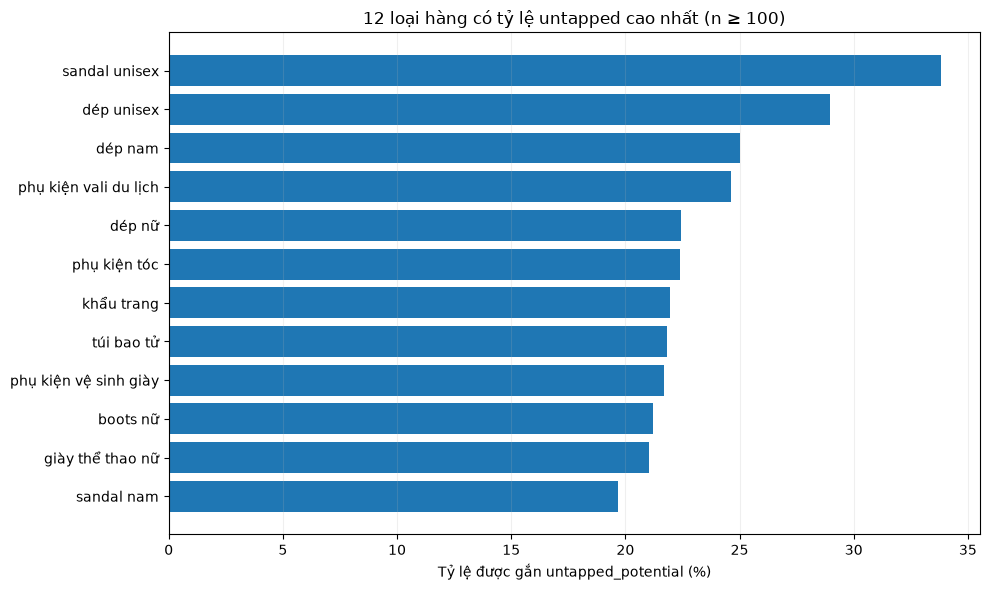

In [4]:
MIN_TYPE_N = 100   # chỉnh ở đây nếu cần, nhưng ghi rõ threshold trong báo cáo

by_type = pd.crosstab(statuses['product_type'], statuses['status'])
by_type['total'] = by_type.sum(axis=1)
for col in ['untapped_potential','difficult_to_sell','insufficient_data','performing_well']:
    if col not in by_type: by_type[col] = 0
by_type['untapped_rate_pct'] = 100 * by_type['untapped_potential'] / by_type['total']
by_type['insufficient_rate_pct'] = 100 * by_type['insufficient_data'] / by_type['total']
by_type = by_type.reset_index()
by_type.to_csv(OUT / 'insight_A_status_by_product_type.csv', index=False, encoding='utf-8-sig')

eligible = by_type.loc[by_type['total'] >= MIN_TYPE_N].copy()
top_type = eligible.sort_values(['untapped_rate_pct','total'],ascending=[False,False]).head(12)
print(f'Nhóm có tối thiểu {MIN_TYPE_N} sản phẩm: {len(eligible)} / {len(by_type)}')
display(top_type[['product_type','total','untapped_potential','untapped_rate_pct','insufficient_rate_pct']]
        .round(2).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10,6))
ax.barh(top_type['product_type'].iloc[::-1], top_type['untapped_rate_pct'].iloc[::-1])
ax.set_xlabel('Tỷ lệ được gắn untapped_potential (%)')
ax.set_title(f'12 loại hàng có tỷ lệ untapped cao nhất (n ≥ {MIN_TYPE_N})')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

### A2 · Từng nhóm thường được đề xuất kiểm tra điều gì?

Cảnh báo quan trọng: rule `review_visibility_and_stock` được NL gắn cho **mọi sản phẩm** thuộc `untapped_potential` theo thiết kế. Nó *không phải* một insight khám phá độc lập. Ta xem thêm 4–5 đề xuất khác và tính **% sản phẩm trong nhóm nhận từng rule**.

,rule_id,n_products,pct_untapped
0,review_visibility_and_stock,5892,100.0
1,add_product_images,2670,45.3
2,review_price_positioning,2154,36.6
3,consider_product_video,632,10.7
4,improve_product_description,328,5.6


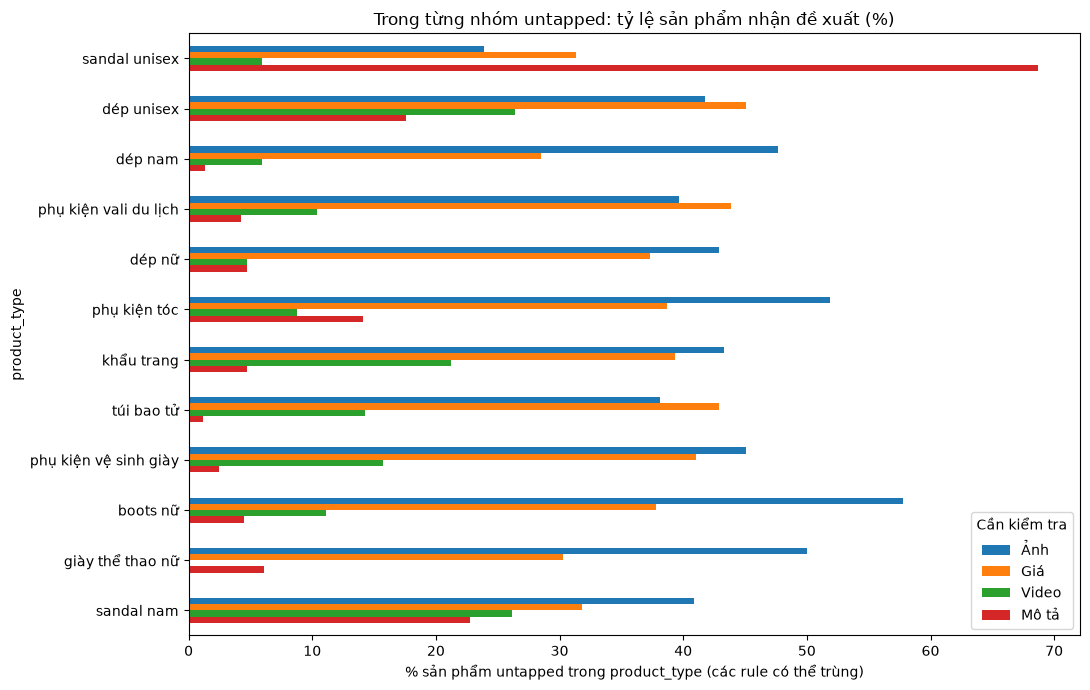

In [5]:
untapped = statuses.loc[statuses['status']=='untapped_potential',['product_id','product_type']].copy()
untapped_rules = joined.loc[joined['status']=='untapped_potential', ['product_id','product_type','rule_id']].drop_duplicates()
counts_type = untapped.groupby('product_type')['product_id'].nunique().rename('untapped_n')
actions_type = (untapped_rules.groupby(['product_type','rule_id'])['product_id']
                .nunique().unstack(fill_value=0))
actions_pct = actions_type.div(counts_type,axis=0).mul(100).rename(columns=lambda x: x+'__pct')
actions_merged = actions_type.join(actions_pct).join(counts_type).reset_index()
actions_merged.to_csv(OUT/'insight_A_action_mix_by_type.csv',index=False,encoding='utf-8-sig')

common = (untapped_rules.groupby('rule_id')['product_id'].nunique()
          .sort_values(ascending=False).rename('n_products').reset_index())
common['pct_untapped'] = (100*common['n_products']/len(untapped)).round(1)
display(common)

shown_rules = ['add_product_images','review_price_positioning',
               'consider_product_video','improve_product_description']
selected = actions_pct.reindex(top_type['product_type']).reindex(
    columns=[r+'__pct' for r in shown_rules], fill_value=0).fillna(0)
selected.columns = ['Ảnh','Giá','Video','Mô tả']
if not selected.empty:
    ax=selected.plot(kind='barh',figsize=(11,7))
    ax.set_title('Trong từng nhóm untapped: tỷ lệ sản phẩm nhận đề xuất (%)')
    ax.set_xlabel('% sản phẩm untapped trong product_type (các rule có thể trùng)')
    ax.invert_yaxis()
    ax.legend(title='Cần kiểm tra',loc='lower right')
    plt.tight_layout()
    plt.show()

## 3 · INSIGHT B — Listing Gap: Chênh lệch giá và số ảnh so với peer

NL đã có rule và `evidence` dạng văn bản. **Giá trị bổ sung của bạn** là biến các bằng chứng rời rạc thành số đo/tổng hợp dễ đọc trên UI, kèm case cụ thể để kiểm chứng.

Chúng ta *chỉ trích xuất khoảng cách* ở những dòng **đã được rule gắn cờ**; không được hiểu là phân phối gap của toàn bộ sản phẩm. Đặc biệt, các rule này có thể xuất hiện cả ở sản phẩm `performing_well`.

GIÁ: trích xuất 14,080/14,080 evidence (100.0%)
ẢNH: trích xuất 15,966/15,966 evidence (100.0%)
Giá: % chênh lệch ở những SP đã bị gắn rule:


,count,mean,std,min,25%,50%,75%,90%,max
price_gap_pct,14080.0,186.59,502.94,15.0,37.0,75.0,163.0,370.0,25900.0


Ảnh: số ảnh ít hơn peer trong những SP đã bị gắn rule:


,count,mean,std,min,25%,50%,75%,90%,max
image_gap_count,15966.0,2.84,1.8,0.0,1.0,2.0,4.0,5.0,39.0


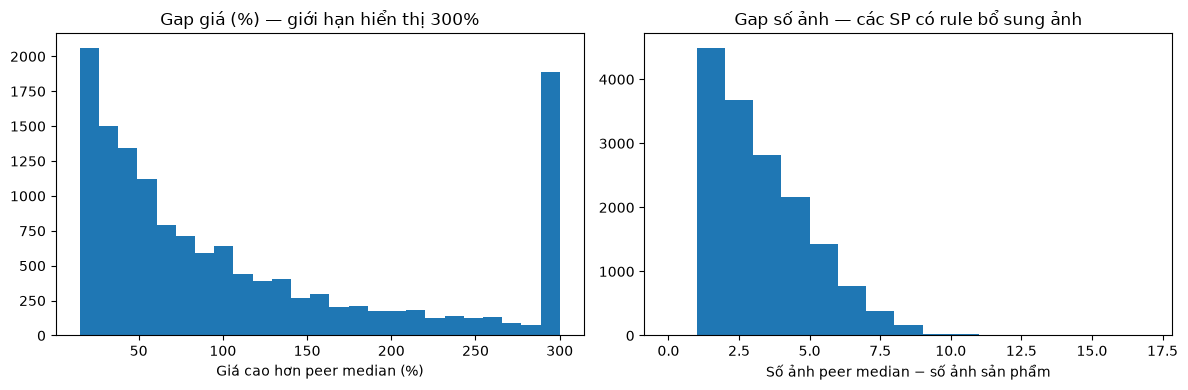

In [6]:
# Chỉ đọc từ evidence, không tính mới/ghi đè output của NL.
price_ev = joined.loc[joined['rule_id']=='review_price_positioning'].copy()
price_ev['price_gap_pct'] = pd.to_numeric(
    price_ev['evidence'].str.extract(r'Giá cao hơn trung vị peer\s+([0-9.,]+)%',expand=False)
        .str.replace(',','.',regex=False), errors='coerce'
)

image_ev = joined.loc[joined['rule_id']=='add_product_images'].copy()
image_parts = image_ev['evidence'].str.extract(
    r'Sản phẩm có\s+(\d+)\s+ảnh;\s+trung vị peer là\s+(\d+)', expand=True)
image_ev['own_images'] = pd.to_numeric(image_parts[0],errors='coerce')
image_ev['peer_median_images'] = pd.to_numeric(image_parts[1],errors='coerce')
image_ev['image_gap_count'] = image_ev['peer_median_images'] - image_ev['own_images']

for title, frame, col in [
    ('GIÁ',price_ev,'price_gap_pct'),('ẢNH',image_ev,'image_gap_count')]:
    parsed = frame[col].notna().sum()
    print(f'{title}: trích xuất {parsed:,}/{len(frame):,} evidence '
          f'({100*parsed/max(len(frame),1):.1f}%)')
    if parsed < len(frame):
        display(frame.loc[frame[col].isna(),['product_id','evidence']].head(5))

print('Giá: % chênh lệch ở những SP đã bị gắn rule:')
display(price_ev['price_gap_pct'].describe(percentiles=[.25,.5,.75,.9]).to_frame().T.round(2))
print('Ảnh: số ảnh ít hơn peer trong những SP đã bị gắn rule:')
display(image_ev['image_gap_count'].describe(percentiles=[.25,.5,.75,.9]).to_frame().T.round(2))

fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].hist(price_ev['price_gap_pct'].dropna().clip(upper=300),bins=25)
axes[0].set_title('Gap giá (%) — giới hạn hiển thị 300%')
axes[0].set_xlabel('Giá cao hơn peer median (%)')
axes[1].hist(image_ev['image_gap_count'].dropna(),bins=range(0,18))
axes[1].set_title('Gap số ảnh — các SP có rule bổ sung ảnh')
axes[1].set_xlabel('Số ảnh peer median − số ảnh sản phẩm')
plt.tight_layout()
plt.show()

### B2 · Gap kép và nhóm hàng nổi bật

Sản phẩm nhận cả hai rule `review_price_positioning` **và** `add_product_images` có hai loại chênh lệch cần kiểm tra. Đây là một **tín hiệu để ưu tiên review**, không chứng minh đó là hai nguyên nhân khiến sản phẩm bán ít.

In [7]:
flags = (joined[joined['rule_id'].isin(['review_price_positioning','add_product_images'])]
         [['product_id','rule_id']].drop_duplicates()
         .assign(present=1)
         .pivot(index='product_id',columns='rule_id',values='present').fillna(0))
for col in ['review_price_positioning','add_product_images']:
    if col not in flags: flags[col] = 0
flags['both_price_and_image'] = (
    flags['review_price_positioning'].eq(1) & flags['add_product_images'].eq(1))
flagged = statuses[['product_id','product_name','product_type','status',
                     'observed_sales','reference_sales','opportunity_score']].merge(
    flags[['both_price_and_image']],left_on='product_id',right_index=True,how='left',validate='one_to_one')
flagged['both_price_and_image'] = flagged['both_price_and_image'].fillna(False).astype(bool)

print('Sản phẩm có đồng thời 2 rule:', int(flagged['both_price_and_image'].sum()))
print('Tỷ lệ trên toàn bộ sản phẩm: %.2f%%'%(100*flagged['both_price_and_image'].mean()))
print('Tỷ lệ trên nhóm untapped: %.2f%%'%(100*flagged.loc[
    flagged.status.eq('untapped_potential'),'both_price_and_image'].mean()))

# Denominator = TOÀN BỘ sản phẩm mỗi loại, đảm bảo không thiên lệch về số recommendation.
gap_type = flagged.groupby('product_type').agg(
    total=('product_id','size'),
    both_gaps=('both_price_and_image','sum'),
).reset_index()
gap_type['both_gap_rate_pct'] = 100*gap_type['both_gaps']/gap_type['total']
gap_type.to_csv(OUT/'insight_B_gap_by_product_type.csv',index=False,encoding='utf-8-sig')
display(gap_type[gap_type['total']>=MIN_TYPE_N]
        .sort_values('both_gap_rate_pct',ascending=False).head(12).round(2))

# Tính hành động được đề xuất ở cả status khác — tránh suy luận nhầm rằng rule chỉ áp dụng cho SP bán thấp.
display(flagged.groupby('status')['both_price_and_image'].agg(['size','sum','mean'])
        .rename(columns={'size':'n_products','sum':'both_gap_n','mean':'both_gap_rate'}).round(3))

Sản phẩm có đồng thời 2 rule: 6136
Tỷ lệ trên toàn bộ sản phẩm: 14.76%
Tỷ lệ trên nhóm untapped: 16.51%


,product_type,total,both_gaps,both_gap_rate_pct
53,túi tote,675,147,21.78
40,phụ kiện tóc,2033,415,20.41
61,tất vớ,2189,439,20.05
42,phụ kiện vali du lịch,666,132,19.82
33,khẩu trang,579,114,19.69
8,dép khác,650,127,19.54
11,dép unisex,314,61,19.43
43,phụ kiện vệ sinh giày,1493,284,19.02
51,túi du lịch,133,25,18.80
58,túi xách nữ,595,110,18.49


,n_products,both_gap_n,both_gap_rate
status,,,
difficult_to_sell,12380,2116,0.171
insufficient_data,5128,29,0.006
performing_well,18176,3018,0.166
untapped_potential,5892,973,0.165


### B3 · Case để kiểm tra thủ công trước khi đưa vào web

Lấy tối đa 30 sản phẩm `untapped_potential` có cả 2 gap, ưu tiên `opportunity_score` cao. Xuất evidence, giả thuyết và bước xác minh từ NL. **Cần người xem thủ công và kiểm tra peer**; đây không phải danh sách đã xác nhận nên tăng giá/trang bị ảnh.

In [8]:
case_ids = (flagged[flagged.status.eq('untapped_potential') & flagged.both_price_and_image]
            .sort_values('opportunity_score',ascending=False)
            .head(30)[['product_id','product_name','product_type','observed_sales',
                       'reference_sales','opportunity_score']])
case_rows = case_ids.merge(
    joined[['product_id','rule_id','evidence','hypothesis','action','validation_needed']],
    on='product_id',how='left',validate='one_to_many')
case_rows.to_csv(OUT/'insight_B_30_manual_review_cases.csv',index=False,encoding='utf-8-sig')
display(case_rows[['product_id','product_name','product_type','rule_id','evidence']].head(16))
print('Đã xuất',case_rows.product_id.nunique(),'sản phẩm để manual review.')

,product_id,product_name,product_type,rule_id,evidence
0,261028652,Combo 3 đôi tất cổ trung nam nữ (unisex) sợi cotton thoáng khí khử mùi - CB2U004,tất vớ,review_visibility_and_stock,Sản phẩm chưa phát sinh bán hàng nhưng có xác suất bán được tham chiếu cao.
1,261028652,Combo 3 đôi tất cổ trung nam nữ (unisex) sợi cotton thoáng khí khử mùi - CB2U004,tất vớ,review_price_positioning,Giá cao hơn trung vị peer 196%.
2,261028652,Combo 3 đôi tất cổ trung nam nữ (unisex) sợi cotton thoáng khí khử mùi - CB2U004,tất vớ,add_product_images,Sản phẩm có 4 ảnh; trung vị peer là 8.
3,249961289,"Chai lau tẩy trắng giày dép, túi xách Plac",phụ kiện vệ sinh giày,review_visibility_and_stock,Sản phẩm chưa phát sinh bán hàng nhưng có xác suất bán được tham chiếu cao.
4,249961289,"Chai lau tẩy trắng giày dép, túi xách Plac",phụ kiện vệ sinh giày,review_price_positioning,Giá cao hơn trung vị peer 79%.
5,249961289,"Chai lau tẩy trắng giày dép, túi xách Plac",phụ kiện vệ sinh giày,add_product_images,Sản phẩm có 2 ảnh; trung vị peer là 5.
6,207807468,"Bóp, Ví Nam Nhỏ Gọn Nhiều Ngăn Tiện Lợi Phong Cách Hàn Quốc - Hàng Chính Hãng",ví nam,review_visibility_and_stock,Sản phẩm chưa phát sinh bán hàng nhưng có xác suất bán được tham chiếu cao.
7,207807468,"Bóp, Ví Nam Nhỏ Gọn Nhiều Ngăn Tiện Lợi Phong Cách Hàn Quốc - Hàng Chính Hãng",ví nam,review_price_positioning,Giá cao hơn trung vị peer 35%.
8,207807468,"Bóp, Ví Nam Nhỏ Gọn Nhiều Ngăn Tiện Lợi Phong Cách Hàn Quốc - Hàng Chính Hãng",ví nam,add_product_images,Sản phẩm có 6 ảnh; trung vị peer là 7.
9,207807468,"Bóp, Ví Nam Nhỏ Gọn Nhiều Ngăn Tiện Lợi Phong Cách Hàn Quốc - Hàng Chính Hãng",ví nam,consider_product_video,Không có video; 43% trong 7 peer bán ở nhóm trên và biết rõ trạng thái video có video.


Đã xuất 30 sản phẩm để manual review.


## 4 · Bổ sung nếu có `clean_products.csv`: video theo loại hàng + phân khúc giá

Mục đích: **kiểm tra** kết quả EDA cũ “listing có video có median sales cao hơn” có còn xuất hiện khi so trong `product_type` và nhóm giá không.

Phương pháp:
1. Join giá & video từ `clean_products.csv` với `observed_sales`, `product_type` của **status v2**.
2. Trong **từng** `product_type`, chia giá thành 4 nhóm theo percentile rank (không dùng 4 ngưỡng giá toàn cục).
3. Chỉ giữ nhóm đủ ít nhất **10 có video** và **20 không video**.
4. Tính hiệu sold-rate = `P(sold>0 | video) − P(sold>0 | không video)` trong mỗi nhóm. Tổng hợp có trọng số cho các nhóm được giữ.

Đây là so sánh mô tả; seller, mức độ phổ biến, tuổi listing và nhiều yếu tố khác chưa được kiểm soát. Không dùng nó để khẳng định video có tác động nhân quả.

Hợp lệ: 41,575 SP; 114 strata cùng type + tier đạt ngưỡng
Chênh lệch sold-rate có trọng số trên nhóm đủ mẫu (điểm phần trăm): 21.43


,product_type,strata_count,matched_n,delta_sold_rate_pp
19,mũ nón,4,3412,15.40
0,balo,4,2369,25.38
36,tất vớ,4,2189,40.06
23,phụ kiện tóc,4,2033,17.07
39,ví nam,4,1708,28.93
29,thắt lưng,4,1581,40.17
35,túi đeo chéo,4,1560,21.16
25,phụ kiện vệ sinh giày,4,1493,14.48
22,phụ kiện thời trang khác,4,1393,21.49
31,túi laptop công sở,4,1364,17.51


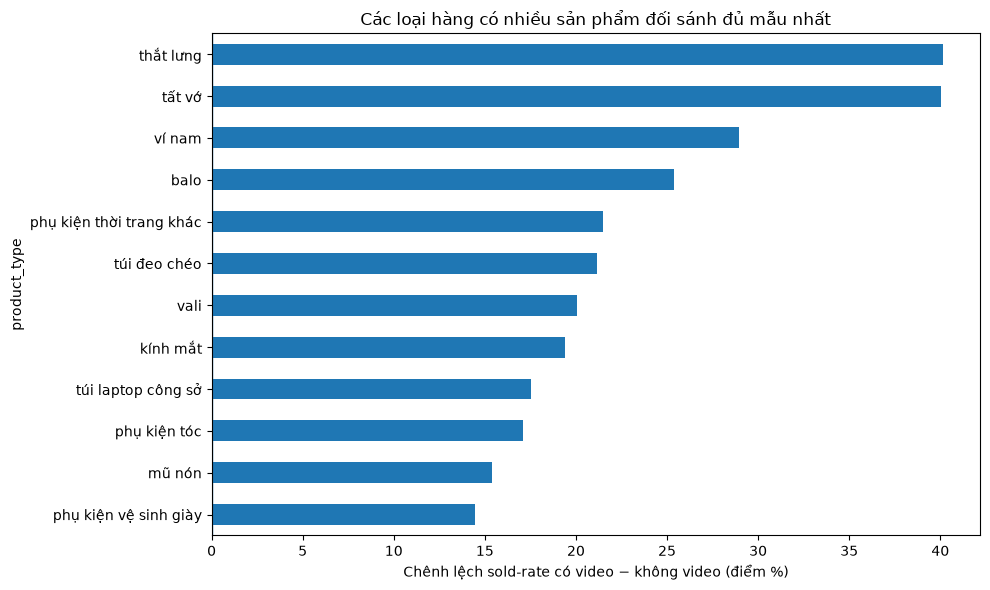

In [9]:
video_result = None
if not CLEAN_PATH.is_file():
    print('⏭ Bỏ qua video: chưa có',CLEAN_PATH)
    print('Xin NL clean_products.csv rồi chạy lại notebook; phần 2 insight chính vẫn hoàn thành.')
else:
    clean = pd.read_csv(CLEAN_PATH,dtype={'product_id':'string'},low_memory=False)
    need = {'product_id','price','has_video'}
    missing = need-set(clean.columns)
    if missing:
        print('⏭ clean_products.csv chưa đúng contract; thiếu:',sorted(missing))
    elif clean.product_id.duplicated().any():
        print('⏭ clean_products.csv có ID trùng — cần xử lý trước khi so sánh.')
    else:
        base = statuses[['product_id','product_type','observed_sales']].merge(
            clean[['product_id','price','has_video']],on='product_id',how='inner',validate='one_to_one')
        base['price'] = pd.to_numeric(base.price,errors='coerce')
        video_str = base['has_video'].astype('string').str.strip().str.lower()
        bool_map = {'true':True,'1':True,'1.0':True,'yes':True,'có':True,
                    'false':False,'0':False,'0.0':False,'no':False,'không':False}
        base['video_flag'] = video_str.map(bool_map)
        unmatched = int(base.video_flag.isna().sum())
        if unmatched:
            print(f'Loại {unmatched:,} dòng không xác định được has_video')
        base = base[(base.price>0)&base.price.notna()&base.video_flag.notna()].copy()
        base['video_flag']=base['video_flag'].astype(bool)
        base['sold_flag']=base['observed_sales'].gt(0)
        if base.empty:
            print('⏭ Không có dữ liệu hợp lệ để kiểm tra video.')
        else:
            # Giá bị trùng nhau: rank(method=average) để giữ các giá bằng nhau cùng phân khúc.
            price_pct = base.groupby('product_type')['price'].rank(method='average',pct=True)
            base['price_tier'] = np.ceil(price_pct*4).clip(1,4).astype('int8')
            agg=(base.groupby(['product_type','price_tier','video_flag'],observed=True)
                 .agg(n=('product_id','size'),sold_rate=('sold_flag','mean'),
                      median_sales=('observed_sales','median')).reset_index())
            yes=agg[agg.video_flag].drop(columns='video_flag').rename(columns={
                'n':'n_video','sold_rate':'rate_video','median_sales':'median_video'})
            no=agg[~agg.video_flag].drop(columns='video_flag').rename(columns={
                'n':'n_no_video','sold_rate':'rate_no_video','median_sales':'median_no_video'})
            matched=yes.merge(no,on=['product_type','price_tier'],how='inner')
            video_result=matched[(matched.n_video>=10)&(matched.n_no_video>=20)].copy()
            video_result['delta_sold_rate_pp']=100*(video_result.rate_video-video_result.rate_no_video)
            video_result['weight']=video_result[['n_video','n_no_video']].min(axis=1)
            video_result.to_csv(OUT/'insight_optional_video_stratified.csv',index=False,encoding='utf-8-sig')
            print(f'Hợp lệ: {len(base):,} SP; {len(video_result)} strata cùng type + tier đạt ngưỡng')
            if video_result.empty:
                print('Không đủ nhóm để kết luận mô tả; giảm ngưỡng phải nêu rõ nếu thực hiện.')
            else:
                print('Chênh lệch sold-rate có trọng số trên nhóm đủ mẫu (điểm phần trăm):',
                      round(np.average(video_result.delta_sold_rate_pp,weights=video_result.weight),2))
                by_video_type = pd.DataFrame([{
                    'product_type':key,'strata_count':len(g),
                    'matched_n':int((g.n_video+g.n_no_video).sum()),
                    'delta_sold_rate_pp':np.average(g.delta_sold_rate_pp,weights=g.weight)}
                    for key,g in video_result.groupby('product_type')])
                show=by_video_type.sort_values('matched_n',ascending=False).head(12)
                display(show.round(2))
                ax=show.sort_values('delta_sold_rate_pp').plot(
                    kind='barh',x='product_type',y='delta_sold_rate_pp',legend=False,figsize=(10,6))
                ax.axvline(0,linewidth=1)
                ax.set_xlabel('Chênh lệch sold-rate có video − không video (điểm %)')
                ax.set_title('Các loại hàng có nhiều sản phẩm đối sánh đủ mẫu nhất')
                plt.tight_layout()
                plt.show()

## 5 · Kết luận có điều kiện + file giao cho nhóm

Cell tiếp theo tạo nháp báo cáo tự động từ số liệu **vừa được chạy**. Đọc lại các case và chỉ chốt insight sau khi nhóm review tính hợp lý của peer / taxonomy. Không gọi “đã chứng minh làm X sẽ tăng sales”.

**Dự kiến chuyển sang prototype:**
- **Màn 1:** Bảng loại hàng, tỷ lệ `untapped_potential`, bộ lọc theo nhóm (hiển thị cả n và %).
- **Màn 2:** Chi tiết sản phẩm → “Listing Gap” dưới dạng giá/ảnh của sản phẩm so với peer, evidence + giả thuyết + việc cần xác minh, kèm chất lượng peer khi NL cung cấp.
- **Demo:** Chọn 1–2 case thực đã review thủ công, không chọn chỉ vì điểm cao.

In [10]:
num_untapped = int((statuses.status=='untapped_potential').sum())
num_both = int(flagged.both_price_and_image.sum())
num_both_untapped = int(flagged.loc[flagged.status=='untapped_potential',
                                    'both_price_and_image'].sum())
top3 = top_type.head(3)
lines = [
    '# Nháp insight Week 2 — sinh từ dữ liệu đã chạy', '',
    f'Run: {metrics.get("scored_at","unknown")} · Model: {", ".join(sorted(versions_s))}', '',
    '## Insight A — Nhóm sản phẩm có nhiều cơ hội chưa khai thác',
    f'- Có {num_untapped:,}/{len(statuses):,} sản phẩm được gắn `untapped_potential` '
    f'({100*num_untapped/len(statuses):.2f}%).',
    f'- Xếp hạng theo tỷ lệ *trong từng product_type* (n ≥ {MIN_TYPE_N}), không xếp theo đếm thô.',
]
for row in top3.itertuples():
    lines.append(f'- {row.product_type}: {int(row.untapped_potential):,}/{int(row.total):,} '
                 f'= {row.untapped_rate_pct:.2f}%.')
lines += ['',
    'Giải thích: tỷ lệ này phản ánh **rule và model scoring**, không phải tỷ lệ tiềm năng thật đã xác nhận.',
    'Tính năng đề xuất: lọc cơ hội theo loại hàng, kèm action mix + bằng chứng của từng listing.', '',
    '## Insight B — Gap giá và ảnh ở các sản phẩm được gắn cờ',
    f'- Có {num_both:,} sản phẩm nhận đồng thời rule rà soát giá và bổ sung ảnh.',
    f'- Trong số đó {num_both_untapped:,} sản phẩm mang nhãn `untapped_potential`.',
    f'- Đã xuất {case_rows.product_id.nunique()} sản phẩm để kiểm tra thủ công (file CSV).',
    'Giải thích: khoảng cách trích từ *evidence* của recommendation, **chỉ trong các listing có rule**.',
    'Tính năng đề xuất: thẻ “Listing Gap” với độ lệch cụ thể + giả thuyết + bước xác minh.', '',
    '## Điều kiện trước khi nói với BGK',
    '- Taxonomy holdout được báo cáo 63%, holdout nhãn v1 chưa cập nhật theo taxonomy v2.',
    '- Peer v2 chưa được đánh giá thủ công đầy đủ; các số peer cần xác minh.',
    '- Không dùng dữ liệu snapshot để kết luận nhân quả hay dự báo tương lai.',
    '- Xác nhận case với team NL, đánh dấu sai taxonomy/peer/rule trước khi demo.',
]
if video_result is None:
    lines += ['', '## Video (để sau)', '- Chưa có `clean_products.csv`, chưa thể chạy phần video.']
elif video_result.empty:
    lines += ['', '## Video', '- Không có nhóm đủ mẫu theo ngưỡng đã đặt.']
else:
    weighted=np.average(video_result.delta_sold_rate_pp,weights=video_result.weight)
    lines += ['', '## Video (phân tích bổ sung)',
              f'- Chênh lệch sold rate trong các strata đủ mẫu (có trọng số): {weighted:.2f} điểm %.',
              '- Chỉ là mối liên hệ có điều kiện theo type + nhóm giá, không kết luận nhân quả.']
report='\n'.join(lines)+'\n'
report_path=OUT/'insight_report_draft.md'
report_path.write_text(report,encoding='utf-8')
print(report)
print('✅ Saved:',report_path)
print('✅ Tổng file output:')
for p in sorted(OUT.glob('insight_*')):
    print(' -',p.name)

# Nháp insight Week 2 — sinh từ dữ liệu đã chạy

Run: 2026-10-12T16:25:18.431146+00:00 · Model: j4f-20261011T181008Z

## Insight A — Nhóm sản phẩm có nhiều cơ hội chưa khai thác
- Có 5,892/41,576 sản phẩm được gắn `untapped_potential` (14.17%).
- Xếp hạng theo tỷ lệ *trong từng product_type* (n ≥ 100), không xếp theo đếm thô.
- sandal unisex: 67/198 = 33.84%.
- dép unisex: 91/314 = 28.98%.
- dép nam: 151/604 = 25.00%.

Giải thích: tỷ lệ này phản ánh **rule và model scoring**, không phải tỷ lệ tiềm năng thật đã xác nhận.
Tính năng đề xuất: lọc cơ hội theo loại hàng, kèm action mix + bằng chứng của từng listing.

## Insight B — Gap giá và ảnh ở các sản phẩm được gắn cờ
- Có 6,136 sản phẩm nhận đồng thời rule rà soát giá và bổ sung ảnh.
- Trong số đó 973 sản phẩm mang nhãn `untapped_potential`.
- Đã xuất 30 sản phẩm để kiểm tra thủ công (file CSV).
Giải thích: khoảng cách trích từ *evidence* của recommendation, **chỉ trong các listing có rule**.
Tính năng đề xuất: thẻ “Listing Gap” với độ

### Checklist trước khi bàn giao

- [ ] Hai biểu đồ Insight A được chạy trên output **cùng phiên bản** từ NL.
- [ ] Phân biệt **số sản phẩm** với **số đề xuất** (1 sản phẩm có nhiều đề xuất).
- [ ] Có denominator và kích thước mẫu cho mọi phần trăm theo nhóm.
- [ ] Đã kiểm tra ít nhất 10 case của Insight B; xem nhãn taxonomy/peer có hợp lý không.
- [ ] Có screenshots 2 màn hình prototype: *Danh sách cơ hội* và *Listing Gap chi tiết*.
- [ ] Chỉ đưa lên slide những phát hiện qua review; dùng từ “ghi nhận/được gắn cờ/đáng kiểm tra”, không dùng “gây ra/tăng chắc chắn”.

**Lưu ý:** Số liệu trong notebook mới được tính tại thời điểm bạn bấm Run All. Nếu NL thay output, chạy lại và đối chiếu `model_version`/`scored_at`.